## COMP661 Assignment 3 Canterbury Temperature forecasting 1174130 Ken Livingston

**Part 4 - Sensitivity Analysis and Explainable AI (XAI) for the GNN+RNN Model**

For this part, we'll use the final GNN+RNN model from Part 3 (configuration C). A shared 2-layer GRU (64 units, 60-day window) encodes each station's history, two graph layers exchange information between the five stations, and a shared head forecasts mean daily temperature for t+1 to t+7 at every station.

* *4.1 Sensitivity analysis* We'll retrain the model (3 seeds each) without:
  * all three evaporation features, wind speed, or rainfall (feature removal)
  * each station in turn (station removal).

  As a second robustness check, the trained model is run with one station's sensors "switched off" at forecast time (station outage, no retraining). The feature results are compared with the Part 1 correlation analysis.

  Then we'll run a perturbation-sensitivity to see how temperatures respond to shifts in inputs.

* *4.2 Explainable AI* We'll use three methods, all implemented directly in PyTorch:
  * Integrated gradients (local): How much each input value moved one forecast
  * Occlusion (local): How much one forecast changes when a feature is replaced by its normal value
  * Permutation importance (global): How much test error grows when a feature's values are shuffled.

  These are applied to three test cases at Christchurch Aero (a correctly forecast warm day, a correctly forecast cold day, and a large error) and summarised in a ranked sensitivity table.

* *4.3 Synthesis* The evidence from the data (Part 1), from model behaviour (retraining) and from XAI is combined into key findings, including where the sources agree and where they conflict.

In [1]:
# Import the libraries
import joblib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
import time
import torch
import torch.nn as nn

from IPython.display import Markdown, display
from pathlib import Path

In [ ]:
# Set up the common parameters
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path("..", "..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PART1_MODEL_DIR = PROJECT_ROOT / "Part_1" / "models"
PART3_MODEL_DIR = PROJECT_ROOT / "Part_3" / "models"
FIG_DIR = Path("..", "figures")
MODEL_DIR = Path("..", "models")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RERUN_EXPERIMENTS = False

STATION_INFO = {
    "Christchurch Aero": {"id": "4843",  "folder": "christchurch_aero"},
    "Chch Kyle Street":  {"id": "24120", "folder": "christchurch_kyle_st_ews"},
    "Ashburton Aero":    {"id": "26170", "folder": "ashburton_aero_aws"},
    "Rangiora":          {"id": "17244", "folder": "rangiora_ews"},
    "Hanmer Forest":     {"id": "11234", "folder": "hanmer_forest_ews"},
}
STATIONS = list(STATION_INFO)
FEATURES = ["evap_penman_ow", "evap_penman_pet", "evap_pt_pet",
            "max_temp", "min_temp", "mean_temp", "wind_speed", "rainfall"]
TARGET = "mean_temp"
HORIZON = 7
FEATURE_GROUPS = {"Evaporation (all 3)": ["evap_penman_ow", "evap_penman_pet", "evap_pt_pet"],
                  "Wind speed": ["wind_speed"], "Rainfall": ["rainfall"]}

# Final Part 3 configuration (the model to be analysed here)
part3_config = json.loads((PART3_MODEL_DIR / "final_gnn_rnn_config.json").read_text())
WINDOW, HIDDEN, RNN_LAYERS = part3_config["window_days"], part3_config["hidden_size"], part3_config["rnn_layers"]
DROPOUT, GRAPH_LAYERS, SIGMA_KM = part3_config["dropout"], part3_config["graph_layers"], part3_config["sigma_km"]
BATCH_SIZE, LEARNING_RATE, MAX_EPOCHS, PATIENCE = 64, 1e-3, 100, 10
SEEDS = [0, 1, 2]
PART3_FINAL_CONFIG_LETTER = part3_config["configuration"][0]          # Configuration C

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def column_decimals(column, max_decimals=3):
    values = column.dropna().abs()
    for decimals in range(max_decimals + 1):
        if np.allclose(values, values.round(decimals)):
            return decimals
    return max_decimals

# Table display settings
def show_table(table, title, max_decimals=3):
    display(Markdown(f"**{title}**"))
    float_columns = table.select_dtypes("float").columns
    number_formats = {col: f"{{:.{column_decimals(table[col], max_decimals)}f}}" for col in float_columns}
    display(table.style.format(number_formats, na_rep=""))

print(f"Model analysed: {part3_config['configuration']} – {part3_config['recurrent_cell']} "
      f"{RNN_LAYERS}×{HIDDEN}, {GRAPH_LAYERS} graph layers, {WINDOW}-day window, σ = {SIGMA_KM:.1f} km")

Model analysed: C: T→S, 2 layers, σ=mean – GRU 2×64, 2 graph layers, 60-day window, σ = 78.0 km


In [3]:
# Build the dataset
station_data = {s: pd.read_csv(PROCESSED_DIR / f"{i['folder']}_daily_clean.csv", parse_dates=["date"])
                .set_index("date")[FEATURES] for s, i in STATION_INFO.items()}
dates = station_data[STATIONS[0]].index
split_dates = {k: [pd.Timestamp(d) for d in v]
               for k, v in json.loads((PART1_MODEL_DIR / "split_dates.json").read_text()).items()}
station_scalers = joblib.load(PART1_MODEL_DIR / "feature_scalers.joblib")
scaled_full = {s: station_scalers[s].transform(station_data[s][FEATURES]) for s in STATIONS}   # [days, 8]

# Gaussian edge weights from the Part 3 distances between stations
coords = {"Christchurch Aero": (-43.493, 172.537), "Chch Kyle Street": (-43.531, 172.608),
          "Ashburton Aero": (-43.903, 171.804), "Rangiora": (-43.329, 172.611), "Hanmer Forest": (-42.534, 172.851)}

def haversine_km(a, b):
    lat1, lon1, lat2, lon2 = map(np.radians, (*coords[a], *coords[b]))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6389.0 * np.arcsin(np.sqrt(h))

def adjacency_for(stations):
    w = np.array([[0.0 if a == b else np.exp(-(haversine_km(a, b) / SIGMA_KM) ** 2) for b in stations]
                  for a in stations])
    return w / w.sum(axis=1, keepdims=True)

assert np.allclose(adjacency_for(STATIONS), np.array(part3_config["adjacency"]), atol=1e-5)

def build_dataset(stations, features):  # Graph samples for a subset of stations/features
    feat_idx = [FEATURES.index(f) for f in features]
    target_idx_in = features.index(TARGET)
    scaled = np.stack([scaled_full[s][:, feat_idx] for s in stations], axis=1)
    splits = {}
    for split in ["train", "validation", "test"]:
        first_day, last_day = split_dates[split]
        X, y, start = [], [], []
        for t in range(WINDOW - 1, len(dates) - HORIZON):
            if dates[t + 1] < first_day or dates[t + HORIZON] > last_day:
                continue
            X.append(scaled[t - WINDOW + 1: t + 1])
            y.append(scaled[t + 1: t + 1 + HORIZON, :, target_idx_in].T)
            start.append(dates[t + 1])
        splits[split] = (torch.tensor(np.array(X), dtype=torch.float32),
                         torch.tensor(np.array(y), dtype=torch.float32), pd.DatetimeIndex(start))
    return splits

class GraphLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.self_linear = nn.Linear(in_dim, out_dim)
        self.neighbour_linear = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, h, adjacency):
        neighbour_mean = torch.einsum("ij,...jd->...id", adjacency, h)
        return torch.relu(self.self_linear(h) + self.neighbour_linear(neighbour_mean))

class GNNRNNForecaster(nn.Module):  # Use the temporal then spatial sequence from Part 3

    def __init__(self, order, n_graph_layers, adjacency, n_features=len(FEATURES), hidden=HIDDEN,
                 rnn_layers=RNN_LAYERS, dropout=DROPOUT, horizon=HORIZON):
        super().__init__()
        self.order = order
        self.register_buffer("adjacency", torch.tensor(adjacency, dtype=torch.float32))
        gru_input = hidden if order == "S->T" else n_features
        if order == "S->T":
            dims = [n_features] + [hidden] * n_graph_layers
            self.graph_layers = nn.ModuleList(GraphLayer(dims[k], dims[k + 1]) for k in range(n_graph_layers))
        else:
            self.graph_layers = nn.ModuleList(GraphLayer(hidden, hidden) for _ in range(n_graph_layers))
        self.gru = nn.GRU(gru_input, hidden, num_layers=rnn_layers, dropout=dropout, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, horizon)

    def encode_time(self, x):
        batch, window, nodes, dim = x.shape
        output, _ = self.gru(x.permute(0, 2, 1, 3).reshape(batch * nodes, window, dim))
        return output[:, -1].reshape(batch, nodes, -1)

    def forward(self, x):
        if self.order == "S->T":
            h = x
            for k, layer in enumerate(self.graph_layers):
                update = layer(h, self.adjacency)
                h = update if k == 0 else h + update
            h = self.encode_time(h)
        else:
            h = self.encode_time(x)
            for layer in self.graph_layers:
                h = h + self.dropout(layer(h, self.adjacency))
        return self.head(h)

def predict(model, X, batch_size=256):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])

def target_scale(stations):
    mean = np.array([station_scalers[s].mean_[FEATURES.index(TARGET)] for s in stations])
    std = np.array([station_scalers[s].scale_[FEATURES.index(TARGET)] for s in stations])
    return mean, std

def test_errors_C(model, splits, stations): # Forecast − observed in °C on the test set: [samples, nodes, 7]
    X, y, _ = splits["test"]
    _, std = target_scale(stations)
    return (predict(model, X).numpy() - y.numpy()) * std[None, :, None]

full_data = build_dataset(STATIONS, FEATURES)
print("Full dataset:", {k: tuple(v[0].shape) for k, v in full_data.items()})

Full dataset: {'train': (4941, 60, 5, 8), 'validation': (1067, 60, 5, 8), 'test': (1068, 60, 5, 8)}


Run the model, again with 3 seeds, from Part 3 on the Test dataset to establish a baseline for later assessment.

In [ ]:
def load_part3_run(seed):
    model = GNNRNNForecaster("T->S", GRAPH_LAYERS, adjacency_for(STATIONS))
    model.load_state_dict(torch.load(PART3_MODEL_DIR / "experiment_runs" / f"config_{PART3_FINAL_CONFIG_LETTER}_s{seed}.pt"))
    return model.eval()

def rmse_summary(errors, stations):
    return pd.DataFrame({"RMSE": np.sqrt((errors ** 2).mean(axis=(0, 2))),
                         "RMSE t+1": np.sqrt((errors[:, :, 0] ** 2).mean(axis=0)),
                         "RMSE t+7": np.sqrt((errors[:, :, -1] ** 2).mean(axis=0))}, index=stations)

reference_runs = {seed: rmse_summary(test_errors_C(load_part3_run(seed), full_data, STATIONS), STATIONS) for seed in SEEDS}
reference = sum(reference_runs.values()) / len(SEEDS)
reference_seed_std = pd.concat([r["RMSE"] for r in reference_runs.values()], axis=1).std(axis=1)
final_model = load_part3_run(0)

ref_table = reference.copy()
ref_table["RMSE std over seeds"] = reference_seed_std
ref_table.loc["Mean of 5 stations"] = ref_table.mean()
show_table(ref_table.round(3), "Table 4.1 – Reference: test RMSE (°C) of the full GNN+RNN, mean of 3 seeds")

**Table 4.1 – Reference: test RMSE (°C) of the full GNN+RNN, mean of 3 seeds**

,RMSE,RMSE t+1,RMSE t+7,RMSE std over seeds
Christchurch Aero,3.013,2.588,3.090,0.016
Chch Kyle Street,2.867,2.433,2.944,0.017
Ashburton Aero,3.114,2.724,3.187,0.013
Rangiora,2.907,2.515,2.975,0.017
Hanmer Forest,3.434,2.882,3.526,0.020
Mean of 5 stations,3.067,2.628,3.145,0.017


The RMSE std is the 'noise' level, that ranges between 0.013 and 0.020 - any results we get below that level could be just due to the random initialisation.

**4.1 Sensitivity analysis**

*Experiments: re-training without feature groups or stations*
Each experiment re-trains the complete model from scratch, with exactly the Part 3 architecture and training
settings, 3 seeds, and early stopping on validation:
* Feature removal: the input has 5 (no evaporation) or 7 (no wind / no rain) features per station.  Mean, max and min temperature are always kept, because mean temperature is also the target.
* Station removal: the station is removed from the graph and from training. The model has 4 nodes, and the adjacency is rebuilt from the remaining stations' distances.

Trained weights are saved after every run. If the notebook is interrupted, re-running it re-uses the runs that were already completed and trains only the missing ones. (I had a problem with this in an earlier notebook).

The effect is measured as the change in test RMSE relative to the reference (mean of 3 seeds each).  Positive delta = the model is worse without the feature/station (i.e. it was useful).

In [5]:
RESULTS_FILE = MODEL_DIR / "sensitivity_results.csv"
RUN_DIR = MODEL_DIR / "sensitivity_runs"
RUN_DIR.mkdir(exist_ok=True)

EXPERIMENTS = {f"Without {g.lower()}": {"type": "feature", "stations": STATIONS,
                                        "features": [f for f in FEATURES if f not in cols]}
               for g, cols in FEATURE_GROUPS.items()}
EXPERIMENTS.update({f"Without station {s}": {"type": "station", "stations": [x for x in STATIONS if x != s],
                                              "features": FEATURES} for s in STATIONS})

def train_model(splits, stations, n_features, seed):
    """Train the Part 3 architecture on the given dataset; early stopping on validation loss."""
    set_seed(seed)
    X_train, y_train, _ = splits["train"]
    X_val, y_val, _ = splits["validation"]
    model = GNNRNNForecaster("T->S", GRAPH_LAYERS, adjacency_for(stations), n_features=n_features)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()
    generator = torch.Generator().manual_seed(seed)
    best_val, best_state, wait, epochs = np.inf, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X_train), generator=generator)
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            optimiser.zero_grad()
            loss_fn(model(X_train[batch]), y_train[batch]).backward()
            optimiser.step()
        val_mse = loss_fn(predict(model, X_val), y_val).item()
        epochs = epoch
        if val_mse < best_val - 1e-6:
            best_val, wait = val_mse, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model.eval(), epochs

if RERUN_EXPERIMENTS or not RESULTS_FILE.exists():
    rows = []
    t0 = time.time()
    for name, spec in EXPERIMENTS.items():
        splits = build_dataset(spec["stations"], spec["features"])
        for seed in SEEDS:
            run_start = time.time()
            weights_file = RUN_DIR / f"{name.replace(' ', '_')}_s{seed}.pt"
            meta_file = weights_file.with_suffix(".json")
            if weights_file.exists() and not RERUN_EXPERIMENTS:
                # Resume: re-use a run that was already trained (e.g. after an interruption)
                model = GNNRNNForecaster("T->S", GRAPH_LAYERS, adjacency_for(spec["stations"]),
                                         n_features=len(spec["features"]))
                model.load_state_dict(torch.load(weights_file))
                model.eval()
                epochs = json.loads(meta_file.read_text())["epochs"] if meta_file.exists() else np.nan
            else:
                model, epochs = train_model(splits, spec["stations"], len(spec["features"]), seed)
                torch.save(model.state_dict(), weights_file)
                meta_file.write_text(json.dumps({"epochs": epochs}))
            summary = rmse_summary(test_errors_C(model, splits, spec["stations"]), spec["stations"])
            for station, r in summary.iterrows():
                rows.append({"experiment": name, "type": spec["type"], "seed": seed, "station": station,
                             "RMSE": r["RMSE"], "RMSE t+1": r["RMSE t+1"], "RMSE t+7": r["RMSE t+7"],
                             "epochs": epochs})
            print(f"{name:<34} seed={seed}: mean test RMSE {summary['RMSE'].mean():.3f} °C "
                  f"({time.time() - run_start:.0f} s)")
    sensitivity_results = pd.DataFrame(rows)
    sensitivity_results.to_csv(RESULTS_FILE, index=False)
    print(f"\nAll {len(EXPERIMENTS) * len(SEEDS)} runs finished in {(time.time() - t0) / 60:.1f} min")
else:
    sensitivity_results = pd.read_csv(RESULTS_FILE)
    print(f"Loaded saved results of {sensitivity_results[['experiment', 'seed']].drop_duplicates().shape[0]} runs")

mean_results = sensitivity_results.groupby(["experiment", "station"])[["RMSE", "RMSE t+1", "RMSE t+7"]].mean()

Without evaporation (all 3)        seed=0: mean test RMSE 3.216 °C (357 s)
Without evaporation (all 3)        seed=1: mean test RMSE 3.184 °C (421 s)
Without evaporation (all 3)        seed=2: mean test RMSE 3.255 °C (440 s)
Without wind speed                 seed=0: mean test RMSE 3.076 °C (283 s)
Without wind speed                 seed=1: mean test RMSE 3.072 °C (330 s)
Without wind speed                 seed=2: mean test RMSE 3.051 °C (293 s)
Without rainfall                   seed=0: mean test RMSE 3.075 °C (273 s)
Without rainfall                   seed=1: mean test RMSE 3.077 °C (366 s)
Without rainfall                   seed=2: mean test RMSE 3.054 °C (292 s)
Without station Christchurch Aero  seed=0: mean test RMSE 3.091 °C (211 s)
Without station Christchurch Aero  seed=1: mean test RMSE 3.079 °C (309 s)
Without station Christchurch Aero  seed=2: mean test RMSE 3.068 °C (248 s)
Without station Chch Kyle Street   seed=0: mean test RMSE 3.124 °C (211 s)
Without station Chch Kyle

This shows that removing the evaporation fields gave the highest RMSE values (3.184-3.255°C), which points to these as being the most valuable for prediction.  Removing any of the other fields, and other stations (except Hanmer Forest) didn't affect the RMSE much - they were all between 3.051 and 3.124°C).  Taking out Hanmer, though, improved the outcome, which highlights the variability of Hanmer weather.

To make that a bit easier to read, we'll show the differences.

In [7]:
feature_rows = {}
for group in FEATURE_GROUPS:
    name = f"Without {group.lower()}"
    delta = mean_results.loc[name]["RMSE"].reindex(STATIONS) - reference["RMSE"]
    feature_rows[group] = delta
feature_delta = pd.DataFrame(feature_rows).T
feature_delta["Mean of 5 stations"] = feature_delta.mean(axis=1)
for group in FEATURE_GROUPS:
    name = f"Without {group.lower()}"
    feature_delta.loc[group, "Δ RMSE t+1 (mean)"] = (mean_results.loc[name]["RMSE t+1"].reindex(STATIONS) - reference["RMSE t+1"]).mean()
    feature_delta.loc[group, "Δ RMSE t+7 (mean)"] = (mean_results.loc[name]["RMSE t+7"].reindex(STATIONS) - reference["RMSE t+7"]).mean()
    seed_means = sensitivity_results[sensitivity_results["experiment"] == name].groupby("seed")["RMSE"].mean()
    feature_delta.loc[group, "std over seeds"] = seed_means.std()
feature_delta.loc["(reference seed std)", "Mean of 5 stations"] = pd.concat(
    [r["RMSE"] for r in reference_runs.values()], axis=1).mean(axis=0).std()
show_table(feature_delta.round(3), "Table 4.2 – Feature removal: change in test RMSE (°C) relative to the full model; "
                                   "positive = better with the feature")

**Table 4.2 – Feature removal: change in test RMSE (°C) relative to the full model; positive = better with the feature**

station,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest,Mean of 5 stations,Δ RMSE t+1 (mean),Δ RMSE t+7 (mean),std over seeds
Evaporation (all 3),0.154,0.158,0.136,0.129,0.181,0.152,0.048,0.177,0.035
Wind speed,-0.003,0.000,-0.003,-0.002,0.005,-0.000,0.001,-0.000,0.013
Rainfall,-0.000,0.004,0.004,-0.007,0.009,0.002,0.094,-0.011,0.013
(reference seed std),,,,,,0.016,,,


This shows evaporation as the key element for predicting temperature.  Wind speed and rainfall have a negligible contribution or are unhelpful - they're mostly less than the 'noise' level (up to 0.02) - with one exception.  Rainfall has some useful effect one day ahead, which makes sense - rain the day before is likely to lead to lower temperatures on the day.

How does that look for station removal?

**Table 4.3 – Station removal: change in test RMSE (°C) at the remaining stations; positive = better when that station is included**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest,Mean of remaining
Without Christchurch Aero,,-0.005,-0.000,-0.002,0.003,-0.001
Without Chch Kyle Street,-0.004,,-0.002,-0.003,-0.005,-0.004
Without Ashburton Aero,0.014,0.015,,0.013,0.007,0.012
Without Rangiora,-0.009,-0.006,-0.012,,0.003,-0.006
Without Hanmer Forest,0.009,0.008,0.002,0.006,,0.006


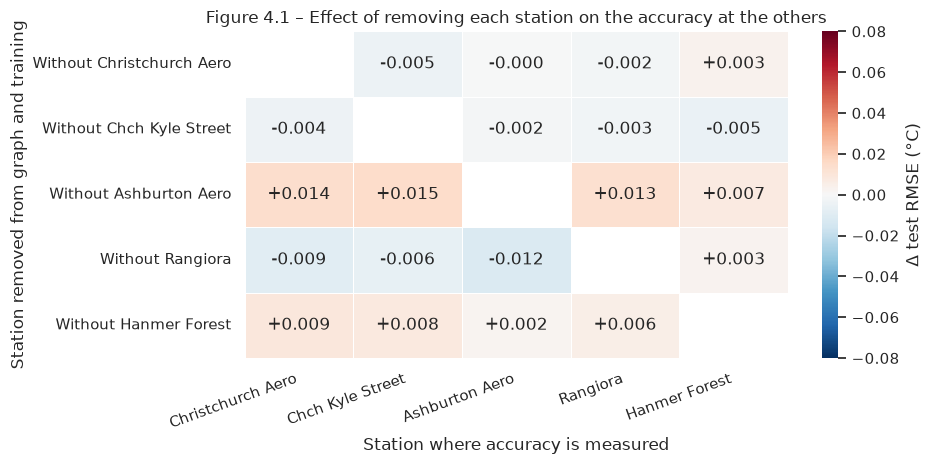

In [8]:
station_delta = pd.DataFrame(index=[f"Without {s}" for s in STATIONS], columns=STATIONS, dtype=float)
for removed in STATIONS:
    name = f"Without station {removed}"
    delta = mean_results.loc[name]["RMSE"] - reference["RMSE"].reindex(mean_results.loc[name].index)
    station_delta.loc[f"Without {removed}", delta.index] = delta.to_numpy()
station_delta["Mean of remaining"] = station_delta.mean(axis=1)
show_table(station_delta.round(3), "Table 4.3 – Station removal: change in test RMSE (°C) at the remaining stations; "
                                   "positive = better when that station is included")

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.heatmap(station_delta[STATIONS], annot=True, fmt="+.3f", cmap="RdBu_r", center=0, vmin=-0.08, vmax=0.08,
            cbar_kws={"label": "Δ test RMSE (°C)"}, ax=ax, linewidths=0.5, linecolor="white")
ax.set_xlabel("Station where accuracy is measured")
ax.set_ylabel("Station removed from graph and training")
ax.set_title("Figure 4.1 – Effect of removing each station on the accuracy at the others")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_station_removal_heatmap.png", dpi=150)
plt.show()

The differences by taking out each station are no better than the noise.  The notable conclusion from this is that Ashburton Aero and Hanmer Forest are better to be included - they very slightly improve the forecasts for the remaining stations, whereas the other 3 stations are relatively tightly clustered (within 7-23km of each other) and can easily substitute for each other.

For an applied example:  How well would this model work if one station was out of action?

In [9]:
X_test, y_test, test_dates = full_data["test"]
_, TARGET_STD = target_scale(STATIONS)
base_errors = (predict(final_model, X_test).numpy() - y_test.numpy()) * TARGET_STD[None, :, None]
base_rmse = np.sqrt((base_errors ** 2).mean(axis=(0, 2)))

outage = pd.DataFrame(index=[f"{s} offline" for s in STATIONS], columns=STATIONS, dtype=float)
for k, failed in enumerate(STATIONS):
    X_failed = X_test.clone()
    X_failed[:, :, k, :] = 0.0
    errors = (predict(final_model, X_failed).numpy() - y_test.numpy()) * TARGET_STD[None, :, None]
    outage.loc[f"{failed} offline"] = np.sqrt((errors ** 2).mean(axis=(0, 2))) - base_rmse
show_table(outage.round(3), "Table 4.4 – Simulated station outage at forecast time: change in test RMSE (°C) of the "
                            "final model (diagonal = the failed station itself)")

**Table 4.4 – Simulated station outage at forecast time: change in test RMSE (°C) of the final model (diagonal = the failed station itself)**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
Christchurch Aero offline,1.324,0.039,-0.002,0.003,0.003
Chch Kyle Street offline,0.026,1.421,-0.005,0.001,-0.001
Ashburton Aero offline,0.001,0.005,1.128,-0.008,-0.001
Rangiora offline,0.036,0.045,-0.008,1.236,0.058
Hanmer Forest offline,-0.003,-0.002,-0.001,-0.010,1.389


As would be expected, the highest RMSE difference is for the station itself.  The biggest impact for all the stations would be if Rangiora is offline.  Rangiora is geographically dead-centre (91km to Ashburton and 91km to Hanmer Forest) and is the 'link' between the Christchurch stations and Hanmer.

**Perturbation sensitivity:** How strongly does the forecast respond to each input?
* Each feature in turn is shifted by −1, −0.5, +0.5 and +1 standard deviation (σ) on every day of the 60-day window, at all five stations, for every test sample.
* Features that cannot be negative (rainfall, wind speed, evaporation) are clipped at zero after the shift, so the model never sees impossible values such as negative rain.
* The response is the mean change in the forecast (°C), averaged over all test samples and stations, at t+1 and t+7. The change in test RMSE is also recorded.

The sensitivity coefficient is the slope of the response, in °C of forecast per σ of input. It is also converted to physical units (e.g. °C per mm) using the average training
standard deviation of each feature across the stations.

**Table 4.4a – Perturbation sensitivity of the forecast to each input (final model, all stations, test set); ranked by |sensitivity at t+1|**

,1 σ in physical units,Sensitivity t+1 (°C per σ),Sensitivity t+7 (°C per σ),Sensitivity t+1 (°C per unit),Response +1σ t+1 (°C),Response −1σ t+1 (°C),Δ RMSE at +1σ (°C),Δ RMSE at −1σ (°C)
mean_temp,4.96 °C,1.451,0.860,0.293,1.462,-1.440,0.239,0.103
evap_pt_pet,1.74 mm,1.360,1.537,0.780,1.753,-0.966,0.728,0.166
min_temp,5.03 °C,1.109,0.922,0.220,1.181,-1.036,0.232,0.079
evap_penman_pet,1.82 mm,0.972,1.733,0.533,1.131,-0.813,0.583,0.181
evap_penman_ow,1.96 mm,-0.838,-0.744,-0.427,-0.945,0.731,0.062,0.124
rainfall,5.99 mm,-0.778,0.023,-0.130,-1.373,0.182,0.085,-0.005
wind_speed,1.23 m/s,-0.734,-0.555,-0.597,-0.775,0.694,0.043,0.171
max_temp,5.79 °C,0.405,-0.421,0.070,0.454,-0.357,0.032,0.123


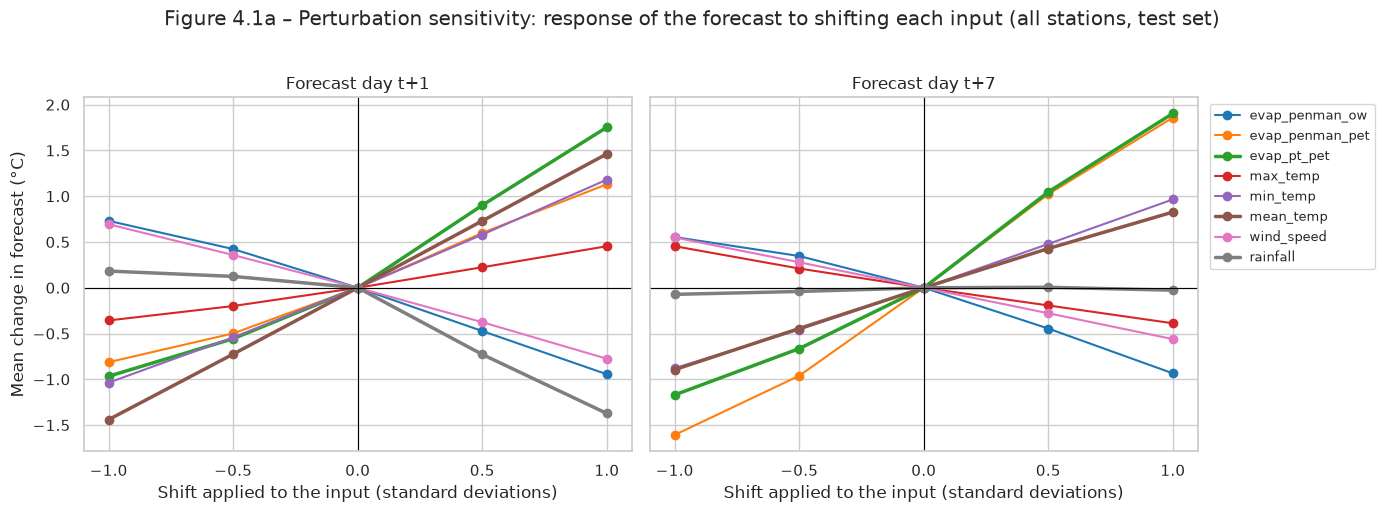

In [11]:
PERTURBATIONS = [-1.0, -0.5, 0.5, 1.0]                       # input shifts in standard deviations
NON_NEGATIVE = ["evap_penman_ow", "evap_penman_pet", "evap_pt_pet", "wind_speed", "rainfall"]

# Physical lower bound (0) of each non-negative feature, in each station's standardised units: [nodes, features]
scaled_floor = np.full((len(STATIONS), len(FEATURES)), -np.inf)
for k, station in enumerate(STATIONS):
    for f, feature in enumerate(FEATURES):
        if feature in NON_NEGATIVE:
            scaled_floor[k, f] = (0.0 - station_scalers[station].mean_[f]) / station_scalers[station].scale_[f]
scaled_floor = torch.tensor(scaled_floor, dtype=torch.float32)

base_forecast_C = predict(final_model, X_test).numpy() * TARGET_STD[None, :, None]       # [samples, nodes, 7]
base_test_rmse = np.sqrt(((base_forecast_C - y_test.numpy() * TARGET_STD[None, :, None]) ** 2).mean())

perturbation_rows = []
for f, feature in enumerate(FEATURES):
    for shift in PERTURBATIONS:
        X_shifted = X_test.clone()
        X_shifted[:, :, :, f] += shift
        X_shifted[:, :, :, f] = torch.maximum(X_shifted[:, :, :, f], scaled_floor[:, f])   # keep physically valid
        forecast_C = predict(final_model, X_shifted).numpy() * TARGET_STD[None, :, None]
        change = forecast_C - base_forecast_C
        perturbation_rows.append({
            "feature": feature, "shift (σ)": shift,
            "mean change t+1 (°C)": change[:, :, 0].mean(),
            "mean change t+7 (°C)": change[:, :, -1].mean(),
            "Δ RMSE all days (°C)": np.sqrt(((forecast_C - y_test.numpy() * TARGET_STD[None, :, None]) ** 2).mean())
                                    - base_test_rmse})
perturbation_results = pd.DataFrame(perturbation_rows)

# Sensitivity coefficients: slope between −1σ and +1σ
units = {"evap_penman_ow": "mm", "evap_penman_pet": "mm", "evap_pt_pet": "mm", "max_temp": "°C",
         "min_temp": "°C", "mean_temp": "°C", "wind_speed": "m/s", "rainfall": "mm"}
mean_std = {feature: np.mean([station_scalers[s].scale_[f] for s in STATIONS]) for f, feature in enumerate(FEATURES)}
sensitivity_rows = {}
for feature in FEATURES:
    r = perturbation_results[perturbation_results["feature"] == feature].set_index("shift (σ)")
    slope_t1 = (r.loc[1.0, "mean change t+1 (°C)"] - r.loc[-1.0, "mean change t+1 (°C)"]) / 2
    slope_t7 = (r.loc[1.0, "mean change t+7 (°C)"] - r.loc[-1.0, "mean change t+7 (°C)"]) / 2
    sensitivity_rows[feature] = {
        "1 σ in physical units": f"{mean_std[feature]:.2f} {units[feature]}",
        "Sensitivity t+1 (°C per σ)": slope_t1,
        "Sensitivity t+7 (°C per σ)": slope_t7,
        "Sensitivity t+1 (°C per unit)": slope_t1 / mean_std[feature],
        "Response +1σ t+1 (°C)": r.loc[1.0, "mean change t+1 (°C)"],
        "Response −1σ t+1 (°C)": r.loc[-1.0, "mean change t+1 (°C)"],
        "Δ RMSE at +1σ (°C)": r.loc[1.0, "Δ RMSE all days (°C)"],
        "Δ RMSE at −1σ (°C)": r.loc[-1.0, "Δ RMSE all days (°C)"],
    }
sensitivity_table = pd.DataFrame(sensitivity_rows).T
sensitivity_table = sensitivity_table.reindex(
    sensitivity_table["Sensitivity t+1 (°C per σ)"].abs().sort_values(ascending=False).index)
numeric_cols = [c for c in sensitivity_table.columns if c != "1 σ in physical units"]
sensitivity_table[numeric_cols] = sensitivity_table[numeric_cols].astype(float)
show_table(sensitivity_table.round(3), "Table 4.4a – Perturbation sensitivity of the forecast to each input "
                                       "(final model, all stations, test set); ranked by |sensitivity at t+1|")

# Response curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
palette = dict(zip(FEATURES, sns.color_palette("tab10", len(FEATURES))))
for ax, col, title in [(axes[0], "mean change t+1 (°C)", "Forecast day t+1"),
                       (axes[1], "mean change t+7 (°C)", "Forecast day t+7")]:
    for feature in FEATURES:
        r = perturbation_results[perturbation_results["feature"] == feature].set_index("shift (σ)")[col]
        r = pd.concat([r, pd.Series({0.0: 0.0})]).sort_index()
        ax.plot(r.index, r.values, marker="o", color=palette[feature], label=feature,
                lw=2.5 if feature in ("evap_pt_pet", "mean_temp", "rainfall") else 1.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xticks([-1, -0.5, 0, 0.5, 1])
    ax.set_xlabel("Shift applied to the input (standard deviations)")
    ax.set_title(title)
axes[0].set_ylabel("Mean change in forecast (°C)")
axes[1].legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Figure 4.1a – Perturbation sensitivity: response of the forecast to shifting each input "
             "(all stations, test set)", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "01a_perturbation_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

* The responses have physically sensible signs. A warmer recent history gives a warmer forecast (mean temperature: +1.45°C per σ at t+1), and more rain gives a colder one (−0.76°C per σ). Higher evaporation, meaning more sun and a later point in the warm season, also gives a warmer forecast.
* Most sensitive at t+1: mean temperature (1.45°C per σ, i.e. around 0.29°C per °C of input), Priestley-Taylor evaporation (1.36°C per σ around 0.78°C per mm) and minimum temperature (1.11°C per σ).
* At t+7 the evaporation features become the most influential. (1.54 and 1.73°C per σ), while the temperature features weaken (0.86–0.92) and rainfall falls to insignificant (0.02). This is the "seasonal clock" again: 7 days ahead the model relies on evaporation for the forecast, while recent temperatures and rain only matter for the next day or two.
* Rainfall's response is strongly one-sided: +1σ (≈ 6 mm more rain every day) cools the t+1 forecast by 1.37°C, but −1σ warms it by only 0.18°C. Most days already have zero rain, so the inputs are clipped at 0. The model has learnt "rain makes it cooler", it's not a symmetric linear relationship.
* Wind speed has a clear effect (−0.75°C per σ at t+1, and −0.55°C at t+7): Windier conditions give a colder forecast. This contrasts with the removal experiment, where re-training without wind cost nothing.  The trained model uses wind, but when wind is not available it can obtain the same information elsewhere.
* Two responses look counter-intuitive: More open-water evaporation gives a colder forecast (−0.84°C per σ), and max temperature has only a small effect, with opposite signs at t+1 and t+7. These might be the side effects of correlated inputs. Shifting one evaporation or temperature feature on its own creates combinations that never occur in reality (e.g. mean temperature no longer equal to (max + min)/2, or open-water evaporation out of line with PET - the other two evaporation measures), so the model reacts to the mismatch. One-at-a-time perturbation describes how the model responds, but for correlated features it should not be read as a physical cause-and-effect.
* Reliability: The RMSE columns show what a systematic sensor bias would cost. A +1σ bias in PET raises the test RMSE by 0.58–0.73°C, in mean or minimum temperature by 0.23-0.24°C, and in wind by 0.04–0.17°C. Errors in the evaporation inputs are the most damaging.

Earlier analysis shows that there is some geographical input, let's see how this matches up against the correlations we found in Part 1.

In [13]:
def anomaly(series):
    return series - series.groupby(series.index.dayofyear).transform("mean")


corr_rows = {}
for feature in FEATURES:
    raw_t7 = np.mean([station_data[s][feature].corr(station_data[s][TARGET].shift(-7)) for s in STATIONS])
    anom_t1 = np.mean([anomaly(station_data[s][feature]).corr(anomaly(station_data[s][TARGET]).shift(-1)) for s in STATIONS])
    anom_t7 = np.mean([anomaly(station_data[s][feature]).corr(anomaly(station_data[s][TARGET]).shift(-7)) for s in STATIONS])
    corr_rows[feature] = {"Part 1: raw r (t+7)": raw_t7, "Part 1: anomaly r (t+1)": anom_t1,
                          "Part 1: anomaly r (t+7)": anom_t7}
corr_table = pd.DataFrame(corr_rows).T

comparison_rows = {}
for group, cols in FEATURE_GROUPS.items():
    comparison_rows[group] = {
        "Part 1: raw |r| (t+7)": corr_table.loc[cols, "Part 1: raw r (t+7)"].abs().max(),
        "Part 1: anomaly |r| (t+1)": corr_table.loc[cols, "Part 1: anomaly r (t+1)"].abs().max(),
        "Part 1: anomaly |r| (t+7)": corr_table.loc[cols, "Part 1: anomaly r (t+7)"].abs().max(),
        "Retraining Δ RMSE all days (°C)": feature_delta.loc[group, "Mean of 5 stations"],
        "Retraining Δ RMSE t+1 (°C)": feature_delta.loc[group, "Δ RMSE t+1 (mean)"],
        "Perturbation |sensitivity| t+1 (°C per σ)": sensitivity_table.loc[cols, "Sensitivity t+1 (°C per σ)"].abs().max(),
        "Perturbation |sensitivity| t+7 (°C per σ)": sensitivity_table.loc[cols, "Sensitivity t+7 (°C per σ)"].abs().max(),
    }
show_table(pd.DataFrame(comparison_rows).T.round(3),
           "Table 4.5 – Feature importance by correlation (Part 1) vs by model sensitivity (retraining and "
           "perturbation); strongest feature in each group")

**Table 4.5 – Feature importance by correlation (Part 1) vs by model sensitivity (retraining and perturbation); strongest feature in each group**

,Part 1: raw |r| (t+7),Part 1: anomaly |r| (t+1),Part 1: anomaly |r| (t+7),Retraining Δ RMSE all days (°C),Retraining Δ RMSE t+1 (°C),Perturbation |sensitivity| t+1 (°C per σ),Perturbation |sensitivity| t+7 (°C per σ)
Evaporation (all 3),0.641,0.250,0.025,0.152,0.048,1.360,1.733
Wind speed,0.174,0.006,0.029,-0.000,0.001,0.734,0.555
Rainfall,0.021,0.216,0.011,0.002,0.094,0.778,0.023


This shows how Part 1 correlations match the analysis here.
* *Evaporation:* **agreement** Has the strongest raw correlation with temperature 7 days later (|r| = 0.64), and it is the feature group whose removal hurts most (+0.148°C). However, its anomaly correlation at t+7 is negligible (0.025). The model therefore uses evaporation for its seasonal information, not for day-to-day weather, which is what the large t+7 retraining effect shows.
* *Wind speed:* **partial disagreement** A weak raw correlation (0.17), no anomaly correlation (≤ 0.03) and no loss when removed all suggest wind is unimportant. Yet the trained model responds clearly to it (0.73°C per σ at t+1). Wind information is available elsewhere (e.g. in Penman open-water evaporation), so the model can do without it, but it does use it when it is there.
* *Rainfall:* **disagreement** The Part 1 headline correlation at t+7 (|r| = 0.02) suggests rainfall is useless, yet removing it worsens t+1 forecasts by +0.094°C. The anomaly correlation at t+1 (|r| = 0.22) explains why.  Rainfall's relationship with temperature is: (1) short-lived, so it vanishes by t+7; (2) hidden by seasonality in raw correlations, because rain falls in all seasons; and (3) non-linear and event-driven - most days have zero rain, so a linear correlation is dominated by dry days, while the occasional heavy-rain day carries the signal (Case 2 below). The perturbation test confirms this: the forecast responds to rain at t+1 (0.78°C per σ) but not at t+7 (0.02).

*Why the two methods sometimes disagree:* Correlation is a single-variable, linear, same-horizon measure. Sensitivity measures what a feature adds in combination with the others, including non-linear effects and different forecast days. A feature can be strongly correlated yet redundant (its information is already in other features), or weakly correlated yet useful (it might still information no other feature has, but only on some days).

**4.2 Explainable AI (XAI)**

We'll use three XAI methods - Integrated Gradients, Occlusion and Permutation Importance.
1. *Integrated gradients (IG):*  A local, gradient-based method. We'll start with a baseline input (all zeros = every feature at its station's normal value), then move the input step by step to the actual input, and the gradient of the forecast is accumulated along the way. Each input value (day × station × feature) receives an attribution in °C. The attributions add up exactly to forecast − baseline forecast (the "completeness" property, checked below). Summing over days and stations gives one score per feature.
2. *Occlusion:*  Again, a local method, this time perturbation-based. One feature at a time is replaced by its baseline value (zero) over the whole 60-day window at all stations, and the change in the forecast (°C) is recorded. It answers "how different would the forecast be without this information?" without using gradients.
3. *Permutation importance:*  A global, model-agnostic method. A feature's 60-day input windows are shuffled between test samples (breaking its link to the target while keeping its distribution), and the increase in test RMSE is measured (5 repeats). Unlike retraining, the model cannot compensate by re-learning.

All local explanations will target the Christchurch Aero forecast for t+1. That is the forecast day where the model has real skill beyond climatology (Parts 2–3); at t+7 it mostly reproduces the seasonal cycle.

In [14]:
EXPLAIN_STATION = "Christchurch Aero"
EXPLAIN_NODE = STATIONS.index(EXPLAIN_STATION)
EXPLAIN_DAY = 0
IG_STEPS = 64

def integrated_gradients(model, x, node, day, steps=IG_STEPS):  # IG attributions (°C) for one sample x [window, nodes, feats] and one output (node, day)
    baseline = torch.zeros_like(x)
    alphas = torch.linspace(0, 1, steps + 1)[1:].view(-1, 1, 1, 1)
    path = (baseline + alphas * (x - baseline)).requires_grad_(True)
    model.eval()
    output = model(path)[:, node, day].sum()
    gradients, = torch.autograd.grad(output, path)
    attributions = (x - baseline) * gradients.mean(dim=0)
    return attributions.detach().numpy() * TARGET_STD[node]

def occlusion(model, x, node, day): # Change in forecast (°C) when each feature is set to its baseline (0) across all days and stations
    with torch.no_grad():
        original = model(x[None])[0, node, day].item()
        changes = {}
        for f, feature in enumerate(FEATURES):
            occluded = x.clone()
            occluded[:, :, f] = 0.0
            changes[feature] = (original - model(occluded[None])[0, node, day].item()) * TARGET_STD[node]
    return pd.Series(changes)

# Completeness check on one test sample
x_check = X_test[100]
ig_check = integrated_gradients(final_model, x_check, EXPLAIN_NODE, EXPLAIN_DAY)
with torch.no_grad():
    f_x = final_model(x_check[None])[0, EXPLAIN_NODE, EXPLAIN_DAY].item() * TARGET_STD[EXPLAIN_NODE]
    f_0 = final_model(torch.zeros_like(x_check)[None])[0, EXPLAIN_NODE, EXPLAIN_DAY].item() * TARGET_STD[EXPLAIN_NODE]
print(f"Completeness check: sum of IG attributions = {ig_check.sum():.3f} °C; "
      f"forecast − baseline forecast = {f_x - f_0:.3f} °C")

Completeness check: sum of IG attributions = 7.687 °C; forecast − baseline forecast = 7.713 °C


The IG attributions for this sample add up to 7.69°C, against an actual difference of 7.71°C between the forecast and the baseline forecast (all inputs at their station averages). The difference of 0.02 % confirms that the IG implementation and its integration steps are accurate enough.

**Selecting the three test cases**
Using the final model's t+1 forecasts at Christchurch Aero on the test set:
* *Correct warm day:* the observed temperature is far above the seasonal average (largest positive anomaly), and the forecast is within 1°C of the observation.
* *Correct cold day:* the largest negative anomaly, again forecast within 1°C.
* *Notable error:* the largest absolute forecast error.

The seasonal average is the smoothed training-period climatology used in Parts 2 and 3.

In [17]:
def climatology_lookup(station):
    train_start, train_end = split_dates["train"]
    t = station_data[station].loc[train_start:train_end, TARGET]
    by_day = t.groupby(t.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    wrapped = pd.concat([by_day.iloc[-15:], by_day, by_day.iloc[:15]])
    return wrapped.rolling(31, center=True).mean().iloc[15:-15]


target_mean_all, target_std_all = target_scale(STATIONS)
forecast_C = predict(final_model, X_test).numpy()[:, EXPLAIN_NODE, EXPLAIN_DAY] * target_std_all[EXPLAIN_NODE] + target_mean_all[EXPLAIN_NODE]
observed_C = y_test.numpy()[:, EXPLAIN_NODE, EXPLAIN_DAY] * target_std_all[EXPLAIN_NODE] + target_mean_all[EXPLAIN_NODE]
season_C = climatology_lookup(EXPLAIN_STATION).reindex(test_dates.dayofyear).to_numpy()
cases_frame = pd.DataFrame({"forecast_C": forecast_C, "observed_C": observed_C, "seasonal_avg_C": season_C},
                           index=test_dates)
cases_frame["anomaly_C"] = cases_frame["observed_C"] - cases_frame["seasonal_avg_C"]
cases_frame["error_C"] = cases_frame["forecast_C"] - cases_frame["observed_C"]
correct = cases_frame[cases_frame["error_C"].abs() <= 1.0]
CASES = {
    "Case 1 – correct warm day": correct["anomaly_C"].idxmax(),
    "Case 2 – correct cold day": correct["anomaly_C"].idxmin(),
    "Case 3 – notable error": cases_frame["error_C"].abs().idxmax(),
}
case_table = cases_frame.loc[list(CASES.values())].copy()
case_table.index = [f"{name} ({day.date()})" for name, day in CASES.items()]
show_table(case_table.round(2), f"Table 4.6 – Selected test cases: {EXPLAIN_STATION}, 1-day-ahead forecast (°C); "
                                "date = the forecast day")

**Table 4.6 – Selected test cases: Christchurch Aero, 1-day-ahead forecast (°C); date = the forecast day**

,forecast_C,observed_C,seasonal_avg_C,anomaly_C,error_C
Case 1 – correct warm day (2025-03-03),18.97,19.9,15.96,3.94,-0.93
Case 2 – correct cold day (2023-03-30),9.54,8.8,13.91,-5.11,0.74
Case 3 – notable error (2024-01-20),18.05,28.1,17.41,10.69,-10.05


The three contrasting cases at Christchurch Aero are:
* *Case 1 (3 Mar 2025):*  A warm late-summer day, 3.9°C above the seasonal average (19.9°C observed), forecast at 19.0°C.
* *Case 2 (30 Mar 2023):*  A cold autumn day, 5.1°C below average (8.8°C observed), forecast at 9.5°C. The day before brought 32.8 mm of rain and a sharp drop to 7.3°C, probably a classic southerly change.
* *Case 3 (20 Jan 2024):* The model's worst forecast on the test set. Very likely that a hot nor'wester pushed the mean temperature to 28.1°C (with a maximum 33.7°C, minimum 22.5°C on that day), which was 10.7°C above average and 8.6 °C warmer than the previous day. The model forecast 18.1°C, an error of almost 10°C.

How do they look for the 60 days leading up?

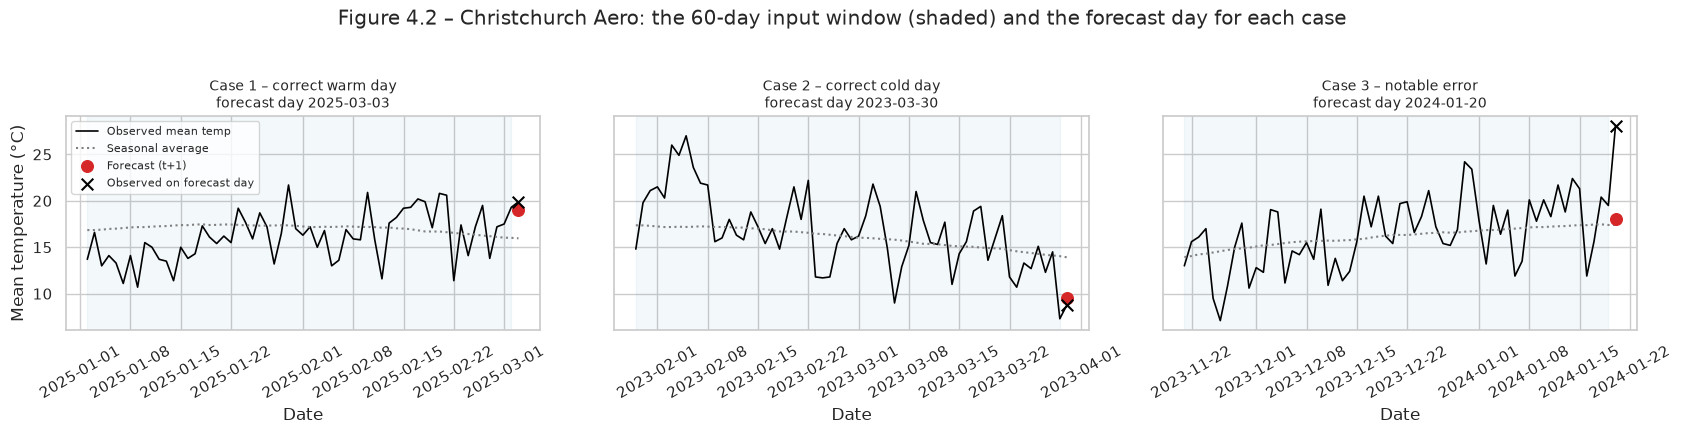

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, (name, day) in zip(axes, CASES.items()):
    window_days = pd.date_range(day - pd.Timedelta(days=WINDOW), day)
    temps = station_data[EXPLAIN_STATION][TARGET].reindex(window_days)
    clim = climatology_lookup(EXPLAIN_STATION).reindex(window_days.dayofyear).to_numpy()
    ax.plot(window_days, temps, color="black", lw=1.2, label="Observed mean temp")
    ax.plot(window_days, clim, color="0.5", ls=":", label="Seasonal average")
    ax.scatter([day], [cases_frame.loc[day, "forecast_C"]], color="#d62728", s=70, zorder=3, label="Forecast (t+1)")
    ax.scatter([day], [cases_frame.loc[day, "observed_C"]], color="black", marker="x", s=70, zorder=3,
               label="Observed on forecast day")
    ax.axvspan(window_days[0], window_days[-2], color="#1f77b4", alpha=0.05)
    ax.set_title(f"{name}\nforecast day {day.date()}", fontsize=10)
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Mean temperature (°C)")
axes[0].legend(fontsize=8, loc="best")
fig.suptitle(f"Figure 4.2 – {EXPLAIN_STATION}: the 60-day input window (shaded) and the forecast day for each case", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_case_context.png", dpi=150, bbox_inches="tight")
plt.show()

The lead-ups a few days in advance explain the outcomes:
* *Case 1:* Temperatures had been rising for several days and were already near 19°C, so persistence and the warm recent trend lead to a good forecast.
* *Case 2:* The window ends with a sudden drop to 7.3°C, and the cold air persisted into the next day, which the model correctly expected.
* *Case 3:* The previous days were warm but ordinary (19–20°C), and the 28°C spike appears out of nowhere. Probably due to a nor'wester, which is driven by large-scale air flow over the Southern Alps, which none of the five stations can pick up in advance.

**Ranked feature-importance for each case**
For each case, IG attributions are summed over the 60 days and five stations to give one value per feature, and we'll show whether the feature pushes the forecast warmer or cooler than the baseline forecast. Occlusion gives the change in forecast when the feature is removed. Bars are ranked by absolute IG.

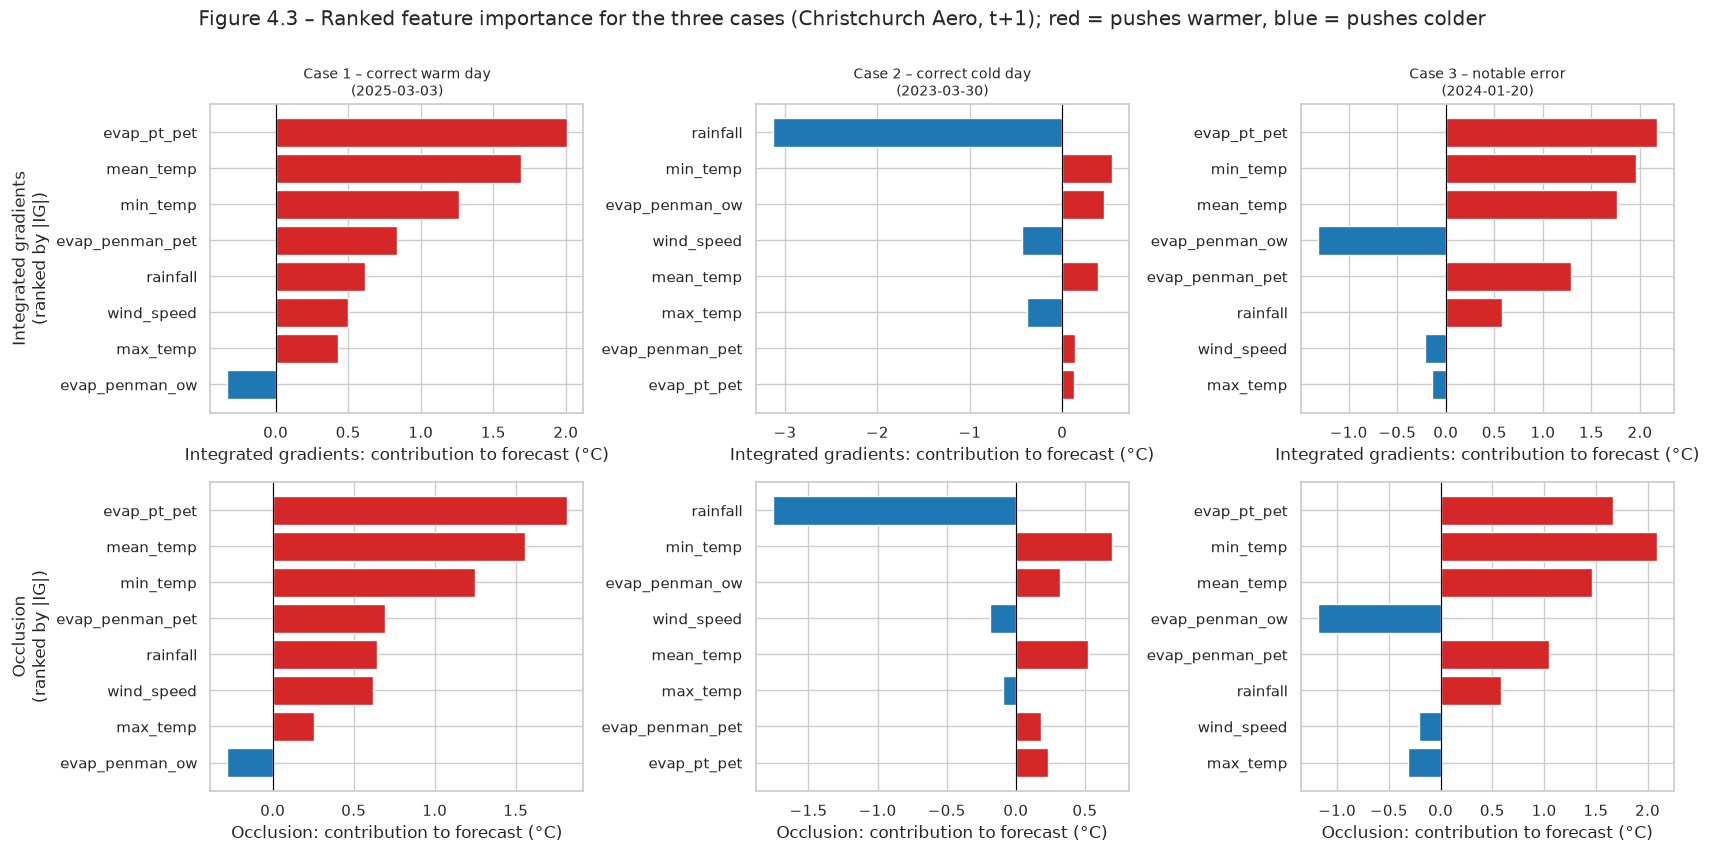

**Table 4.7 – Top three features per case by integrated gradients (signed contribution to the forecast)**

,Case 1,Case 2,Case 3
Case 1 – correct warm day,evap_pt_pet (+2.00 °C),mean_temp (+1.69 °C),min_temp (+1.26 °C)
Case 2 – correct cold day,rainfall (-3.13 °C),min_temp (+0.54 °C),evap_penman_ow (+0.46 °C)
Case 3 – notable error,evap_pt_pet (+2.18 °C),min_temp (+1.96 °C),mean_temp (+1.76 °C)


In [23]:
case_attr = {}
for name, day in CASES.items():
    i = test_dates.get_loc(day)
    ig = integrated_gradients(final_model, X_test[i], EXPLAIN_NODE, EXPLAIN_DAY)        # [window, nodes, feats]
    case_attr[name] = {"ig": ig, "ig_feature": pd.Series(ig.sum(axis=(0, 1)), index=FEATURES),
                       "occlusion": occlusion(final_model, X_test[i], EXPLAIN_NODE, EXPLAIN_DAY)}

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for col, (name, attr) in enumerate(case_attr.items()):
    order = attr["ig_feature"].abs().sort_values().index
    for row, (key, label) in enumerate([("ig_feature", "Integrated gradients"), ("occlusion", "Occlusion")]):
        values = attr[key].reindex(order)
        ax = axes[row, col]
        ax.barh(order, values, color=["#d62728" if v > 0 else "#1f77b4" for v in values])
        ax.axvline(0, color="black", lw=0.8)
        ax.set_xlabel(f"{label}: contribution to forecast (°C)")
        if row == 0:
            ax.set_title(f"{name}\n({CASES[name].date()})", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"{label}\n(ranked by |IG|)")
fig.suptitle(f"Figure 4.3 – Ranked feature importance for the three cases ({EXPLAIN_STATION}, t+1); "
             "red = pushes warmer, blue = pushes colder", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_case_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

case_rank_rows = {}
for name, attr in case_attr.items():
    ranked = attr["ig_feature"].abs().sort_values(ascending=False)
    case_rank_rows[name] = {f"Case {r + 1}": f"{f} ({attr['ig_feature'][f]:+.2f} °C)" for r, f in enumerate(ranked.index[:3])}
show_table(pd.DataFrame(case_rank_rows).T, "Table 4.7 – Top three features per case by integrated gradients "
                                            "(signed contribution to the forecast)")

IG and occlusion agree closely on the ranking and the sign in all three cases, which gives confidence in the explanations.
* *Case 1 (warm day):* The forecast is built from Priestley-Taylor PET (+2.1°C), mean temperature (+1.7°C) and minimum temperature (+1.3°C), all pushing it warmer. High late-summer evaporation and warm recent temperatures together say "warm season, warm spell".
* *Case 2 (cold day):* Rainfall dominates (−3.1°C by IG, −1.7°C by occlusion) and is the only strongly negative contribution. The model has learnt that heavy rain marks a cold change. Temperature features play a minor role, because yesterday's cold temperature on its own would suggest a quicker recovery.
* *Case 3 (error):* the explanation looks almost the same as Case 1: PET, minimum and mean temperature push the forecast warmer by ≈ 1.7–2.4°C each. In other words, the model correctly recognised a warm summer spell, but its evidence pointed to about 18°C. No input carried a signal of the coming 28°C spike, so the error comes from missing information, not from the model misreading its inputs.

**Where and when: attribution by station and by day in the window**
IG attributions can also be summed per station (over all features and days) and per day of the input window (over all features and stations). Let's see how much of each forecast comes from the neighbouring stations through the graph, and how far back in time the model looks.

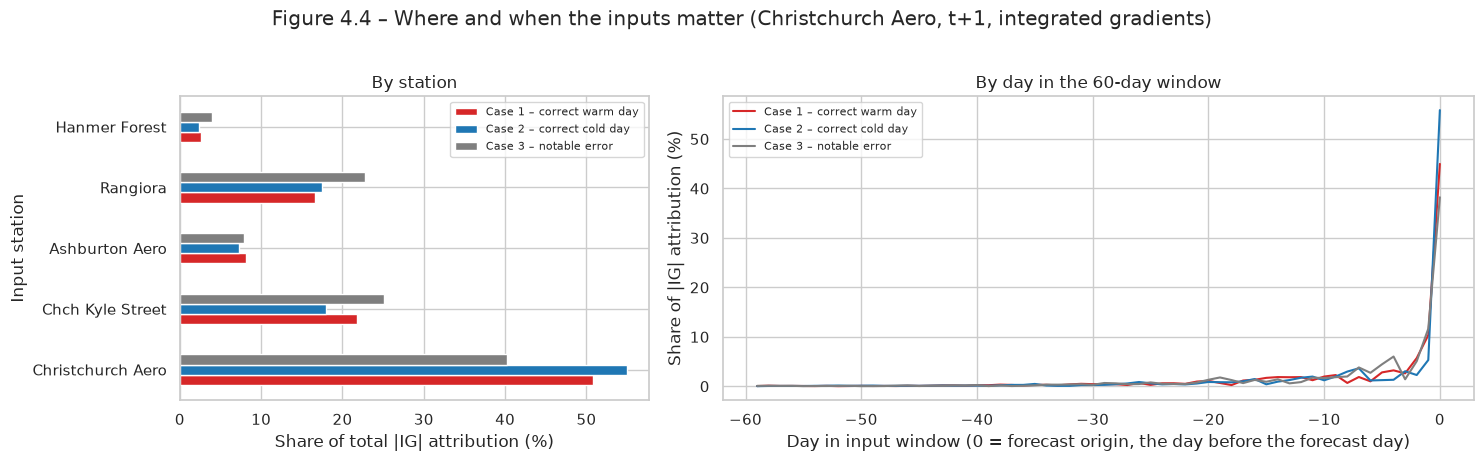

**Table 4.8 – Share of |IG| attribution by input station (%)**

,Case 1 – correct warm day,Case 2 – correct cold day,Case 3 – notable error
Christchurch Aero,50.8,55.0,40.2
Chch Kyle Street,21.8,18.0,25.1
Ashburton Aero,8.2,7.3,7.9
Rangiora,16.6,17.4,22.8
Hanmer Forest,2.7,2.3,3.9


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
by_station = pd.DataFrame({name: np.abs(attr["ig"]).sum(axis=(0, 2)) for name, attr in case_attr.items()},
                          index=STATIONS)
by_station_share = 100 * by_station / by_station.sum()
by_station_share.plot.barh(ax=axes[0], color=["#d62728", "#1f77b4", "#7f7f7f"])
axes[0].set_xlabel("Share of total |IG| attribution (%)")
axes[0].set_ylabel("Input station")
axes[0].set_title("By station")
axes[0].legend(fontsize=8)
lags = np.arange(-WINDOW + 1, 1)
for (name, attr), colour in zip(case_attr.items(), ["#d62728", "#1f77b4", "#7f7f7f"]):
    per_day = np.abs(attr["ig"]).sum(axis=(1, 2))
    axes[1].plot(lags, per_day / per_day.sum() * 100, color=colour, label=name)
axes[1].set_xlabel("Day in input window (0 = forecast origin, the day before the forecast day)")
axes[1].set_ylabel("Share of |IG| attribution (%)")
axes[1].set_title("By day in the 60-day window")
axes[1].legend(fontsize=8)
fig.suptitle(f"Figure 4.4 – Where and when the inputs matter ({EXPLAIN_STATION}, t+1, integrated gradients)", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_attribution_by_station_and_lag.png", dpi=150, bbox_inches="tight")
plt.show()
show_table(by_station_share.round(1), "Table 4.8 – Share of IG attribution by input station (%)")

* *By station:* Christchurch Aero's own inputs account for 38–55% of the attribution to its forecast. The two close neighbours, Chch Kyle Street (18–26%) and Rangiora (17–23%), contribute most of the rest, while Ashburton Aero (7–8%) and Hanmer Forest (2–4%) contribute little. This follows the graph weights (in Table 3.3 of the GNN_RNN_Model notebook). The model does use neighbour information, especially in the error case (Case 3, 62% from neighbours), where its own recent data were least informative.
* *By day:* 37–56% of the attribution falls on the last day of the window, and almost all of it on the last 5–10 days. The other ~50 days contribute only a small, steady background. That background is where the seasonal state comes from, and it explains why the 60-day window still helped in Part 2: a little information from many days adds up.

**Global importance: permutation importance and average |IG|**
To rank the inputs overall, we'll look at two global measures are computed on the test set:
1. *Permutation importance* for each feature: Increase in RMSE (°C), all stations, for all 7 days and separately for t+1, averaged over 5 shuffles.
2. *Mean |IG|*: The average absolute IG attribution per feature over 300 test samples (Christchurch Aero, t+1).

**Table 4.9a – Global importance: permutation importance (all stations) and mean |IG| (Christchurch Aero, t+1)**

,"Permutation Δ RMSE, all days (°C)",± std,"Permutation Δ RMSE, t+1 (°C)","Mean |IG| (°C), CA t+1"
evap_pt_pet,0.983,0.013,0.861,1.568
evap_penman_pet,0.659,0.012,0.374,0.910
mean_temp,0.241,0.008,0.559,1.042
max_temp,0.164,0.007,0.201,0.343
min_temp,0.145,0.007,0.370,0.904
evap_penman_ow,0.107,0.006,0.168,0.610
wind_speed,0.042,0.005,0.056,0.318
rainfall,0.021,0.004,0.269,0.701


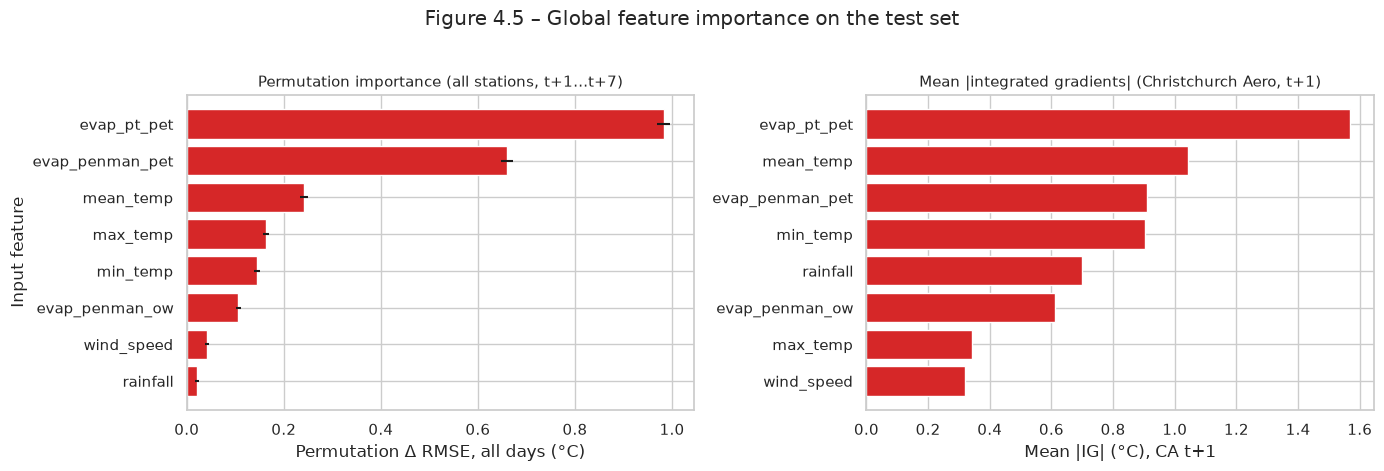

In [24]:
def permutation_importance(model, X, y, feature_index, repeats=5, seed=0):
    rng = np.random.default_rng(seed)
    base = (predict(model, X).numpy() - y.numpy()) * TARGET_STD[None, :, None]
    base_all, base_t1 = np.sqrt((base ** 2).mean()), np.sqrt((base[:, :, 0] ** 2).mean())
    inc_all, inc_t1 = [], []
    for _ in range(repeats):
        X_perm = X.clone()
        X_perm[:, :, :, feature_index] = X[torch.as_tensor(rng.permutation(len(X)))][:, :, :, feature_index]
        err = (predict(model, X_perm).numpy() - y.numpy()) * TARGET_STD[None, :, None]
        inc_all.append(np.sqrt((err ** 2).mean()) - base_all)
        inc_t1.append(np.sqrt((err[:, :, 0] ** 2).mean()) - base_t1)
    return np.mean(inc_all), np.std(inc_all), np.mean(inc_t1)


perm_rows = {}
for f, feature in enumerate(FEATURES):
    mean_all, std_all, mean_t1 = permutation_importance(final_model, X_test, y_test, f)
    perm_rows[feature] = {"Permutation Δ RMSE, all days (°C)": mean_all, "± std": std_all,
                          "Permutation Δ RMSE, t+1 (°C)": mean_t1}
permutation_table = pd.DataFrame(perm_rows).T

sample_idx = np.linspace(0, len(X_test) - 1, 300).astype(int)
mean_abs_ig = np.mean([np.abs(integrated_gradients(final_model, X_test[i], EXPLAIN_NODE, EXPLAIN_DAY,
                                                   steps=32).sum(axis=(0, 1))) for i in sample_idx], axis=0)
permutation_table["Mean |IG| (°C), CA t+1"] = mean_abs_ig

show_table(permutation_table.sort_values("Permutation Δ RMSE, all days (°C)", ascending=False).round(3),
           "Table 4.9a – Global importance: permutation importance (all stations) and mean |IG| (Christchurch Aero, t+1)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, col, title in [(axes[0], "Permutation Δ RMSE, all days (°C)", "Permutation importance (all stations, t+1…t+7)"),
                       (axes[1], "Mean |IG| (°C), CA t+1", f"Mean |integrated gradients| ({EXPLAIN_STATION}, t+1)")]:
    ranked = permutation_table[col].sort_values()
    ax.barh(ranked.index, ranked.values, color="#d62728",
            xerr=permutation_table.loc[ranked.index, "± std"] if col.startswith("Perm") else None)
    ax.set_xlabel(col)
    ax.set_title(title, fontsize=11)
axes[0].set_ylabel("Input feature")
fig.suptitle("Figure 4.5 – Global feature importance on the test set", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_global_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

* *Permutation importance* is dominated by the two evaporation features: shuffling Priestley-Taylor PET raises RMSE by 0.98°C, and Penman PET by 0.66°C. Mean, max and min temperature follow (0.15–0.24°C), then open-water evaporation (0.11°C); wind (0.04°C) and rainfall (0.02°C) are the least important.  Shuffling the PET destroys the model's seasonal clock, which affects all 7 forecast days.
* *Rainfall again depends on the horizon:* - its permutation importance at t+1 (0.27°C) is 13 times its all-days value, and higher than that of max temperature.
* *Mean |IG|* gives a similar top group (PET, mean temperature, Penman PET, min temperature) and ranks rainfall 5th. That is consistent with rainfall's t+1 role.
* The temperature features score lower under permutation than under IG. Mean, max and min temperature carry overlapping information, and so do the neighbouring stations, so when one is shuffled the model can still rely on the others. Permutation importance under-rates correlated features; IG does not.

**Ranked sensitivity table:** - the most influential input variables overall.  
We'll rank the sensitivities on a table that combines all the evidence for each input variable: permutation importance, mean |IG|, the average rank of the variable across the three cases (IG), and the perturbation sensitivity at t+1 (Table 4.4a). Each measure is turned into a rank (1 = most influential), and the overall rank is the average of the four ranks. The retraining result for the variable's group (Table 4.2) is shown alongside, as it measures something different - how much the model loses when it is re-trained without that information.

In [22]:
ranks = pd.DataFrame(index=FEATURES)
ranks["Permutation rank"] = permutation_table["Permutation Δ RMSE, all days (°C)"].rank(ascending=False)
ranks["Mean |IG| rank"] = permutation_table["Mean |IG| (°C), CA t+1"].rank(ascending=False)
ranks["Case IG rank (mean of 3 cases)"] = pd.DataFrame(
    {n: a["ig_feature"].abs().rank(ascending=False) for n, a in case_attr.items()}).mean(axis=1)
ranks["Perturbation rank (t+1)"] = sensitivity_table["Sensitivity t+1 (°C per σ)"].abs().rank(ascending=False)
ranks["Overall score"] = ranks.mean(axis=1)
ranks["Overall rank"] = ranks["Overall score"].rank(method="min").astype(int)
group_of = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
ranks["Retraining Δ RMSE of its group (°C)"] = [feature_delta.loc[group_of[f], "Mean of 5 stations"]
                                                 if f in group_of else np.nan for f in FEATURES]
ranks["Permutation Δ RMSE (°C)"] = permutation_table["Permutation Δ RMSE, all days (°C)"]
ranks["Perturbation sensitivity t+1 (°C per σ)"] = sensitivity_table["Sensitivity t+1 (°C per σ)"]
ranked_table = ranks.sort_values("Overall score")
show_table(ranked_table.round(3), "Table 4.9 – Ranked sensitivity of the input variables (1 = most influential); "
                                  "retraining Δ is blank for temperature features, which were not removed")
top3 = ranked_table.index[:3].tolist()
print("Three most influential input variables overall:", ", ".join(top3))

**Table 4.9 – Ranked sensitivity of the input variables (1 = most influential); retraining Δ is blank for temperature features, which were not removed**

,Permutation rank,Mean |IG| rank,Case IG rank (mean of 3 cases),Perturbation rank (t+1),Overall score,Overall rank,Retraining Δ RMSE of its group (°C),Permutation Δ RMSE (°C),Perturbation sensitivity t+1 (°C per σ)
evap_pt_pet,1,1,3.333,2,1.833,1,0.152,0.983,1.360
mean_temp,3,2,3.333,1,2.333,2,,0.241,1.451
evap_penman_pet,2,3,5.333,4,3.583,3,0.152,0.659,0.972
min_temp,5,4,2.333,3,3.583,4,,0.145,1.109
evap_penman_ow,6,6,5.000,5,5.500,5,0.152,0.107,-0.838
rainfall,8,5,4.000,6,5.750,6,0.002,0.021,-0.778
max_temp,4,7,7.000,8,6.500,7,,0.164,0.405
wind_speed,7,8,5.667,7,6.917,8,-0.000,0.042,-0.734


Three most influential input variables overall: evap_pt_pet, mean_temp, evap_penman_pet


The three most influential input variables overall are:
1. *Priestley-Taylor PET (`evap_pt_pet`):* First by permutation and by mean |IG|, second by perturbation sensitivity, and among the top contributors in two of the three cases.
2. *Mean temperature (`mean_temp`):* Consistently high in every measure, and the most sensitive input at t+1.
3. *Penman PET (`evap_penman_pet`):* Second by permutation importance and the most sensitive input at t+7.

Minimum temperature is a close fourth. Wind speed ranks last overall, although the perturbation test shows the model does respond to it.

**Implications for sensor redundancy and reliability**
* *Wind speed is redundant* for this forecasting task: Removing it and retraining costs nothing, and it ranks last overall. But the current model still responds to wind (0.75°C per σ), so a biased wind sensor would still degrade its forecasts. Since retraining without wind loses nothing, dropping wind removes this vulnerability for free.
* The *three evaporation estimates overlap strongly* (from Part 1, r = 0.67–0.93), but the group as a whole is very useful. Removing all three costs +0.15 °C, and shuffling a single PET costs 0.7–1.0 °C because the model was trained to rely on it. At least one PET series, ideally Priestley-Taylor, should be kept. Because the trained model depends heavily on PET, an error in the evaporation data would directly damage forecast quality.
* *Rainfall is cheap but valuable for next-day forecasts.* It should be kept even though its overall importance looks small.
* *Stations:* for training: The near-duplicate Christchurch-area stations are interchangeable (Table 4.3).  But in operation, every station's own sensors are critical for its own forecast (Table 4.4). Losing them costs 1.1–1.4°C, so the system needs data-quality checks and a fallback.

**4.3 Summary and comparison**

Three sources of evidence are combined:
* *Numerical observations:* The data themselves (Part 1 correlations and anomaly analysis, and the case inputs);
* *Model predictions:* How forecast accuracy changes when the model is re-trained without inputs or stations, or loses a station's data (4.1);
* *Explainable AI (XAI):* Integrated gradients, occlusion and permutation importance (4.2), together with the perturbation sensitivity test (4.1).

Findings supported consistently by all three sources
1. **Evaporation (PET) is the key input, because it encodes the seasonal cycle.**
* *Observations:* Priestley-Taylor PET has the strongest correlation with temperature a week later (r = 0.64), but almost none once the season is removed (0.025). It is a seasonal signal that leads temperature, since sunshine peaks before temperature does.
* *Model predictions:* removing the evaporation features is the only change that clearly hurts (+0.148 °C), most at t+7 (+0.173 °C), where forecasts are essentially seasonal.
* *XAI and sensitivity:* the PET features rank first and third overall. Shuffling Priestley-Taylor PET raises RMSE by ≈ 1 °C, it is the largest contributor in two of the three cases, and PET is the input the forecast is most sensitive to at t+7 (1.5–1.7 °C per σ).

2. **Rainfall matters only for the next day.** Its anomaly correlation is −0.22 at t+1 and ≈ 0 at t+7. Removing it worsens t+1 (+0.09 °C) but not t+7. Its permutation importance at t+1 is 13× its all-days value, and its perturbation sensitivity is 0.76 °C per σ at t+1 against 0.04 at t+7. (Whether rainfall is "important" overall is where the sources disagree; see below.)

3. **Beyond 1–2 days, the predictable signal is the seasonal cycle.** Anomaly correlations vanish by t+3–t+4; all models converge to climatology from t+3 (Parts 2–3); and IG concentrates almost all attribution on the last few days of the window, with only a weak background from earlier days. Case 3, the model's largest error, shows the consequence: a sudden 28 °C nor'wester left no trace in the preceding data, and the XAI explanation shows a forecast built from "ordinary warm spell" evidence.

**Areas where the sources disagree**  
*Wind speed.* The observations give a weak, purely seasonal correlation, retraining without wind gives virtually no loss and the global XAI ranking (last) all suggest wind is unimportant. On the other hand, the perturbation test shows the trained model responds to wind speed (−0.75 °C per σ at t+1). Both are true: the model uses wind when it has it, but the information is redundant, because other inputs (especially Penman open-water evaporation, which is computed with wind speed) can replace it when the model is re-trained. Sensitivity measures reliance; removal measures necessity.

*Rainfall.* The observations at the forecast's horizon (raw correlation at t+7 is close to 0) and global permutation importance (rank 8) suggest it is useless. But re-training without it worsens t+1 forecasts (+0.09 °C), its t+1 permutation importance (0.27 °C) exceeds max temperatures, and in Case 2 it is by far the dominant reason for the correct cold forecast (−3.1 °C). The conflict comes from the timeframe each method averages over. Rainfall's value is short-lived, event-driven and non-linear - it matters on the few days after heavy rain and for next-day forecasts, then disappears in all-horizon or all-day averages and in linear correlations.

*Spatial information.* IG attributes 45–62% of a Christchurch Aero forecast to the neighbouring stations, which suggests the graph matters. Yet re-training without any single station (Table 4.3), or without the graph at all (Part 3), leaves accuracy unchanged within ±0.015°C. Meanwhile the observations show the stations are highly correlated (r = 0.92–0.98). The explanation is redundancy: the model does draw on neighbours when they are available, but their information largely duplicates the station's own. Attribution measures 'what the model used', not 'what it needed'. The outage test adds a further twist: when a station's own data are missing, the neighbours don't make up for it (+1.1–1.4°C), because the model was never trained to work without a station's own inputs.

*Temperature features.* IG ranks mean and minimum temperature 2nd and 4th (which is a bit counter-intuitive), while permutation importance places them below the PET features (3rd and 5th) with much smaller effects. Mean, max and min temperature overlap, and so do the neighbouring stations, so shuffling one leaves the others to carry the information. Permutation importance under-rates such correlated inputs.

**Overall conclusions**
* The GNN+RNN is a seasonally anchored model with a short memory for weather. Evaporation and temperature tell it the season and the current state, and rainfall and recent temperatures adjust the next one or two days.
* The evaporation series and each station's own sensors are critical for reliable forecasts - a 1σ bias in PET raises the error by 0.6–0.7°C, and losing a station's own data raises the error by 1.1–1.4°C. Other inputs (wind in particular) could be reduced without loss, which also removes the model's sensitivity to a faulty wind sensor. 
* Larger gains in 7-day accuracy would need information these sensors do not provide, such as pressure, upstream observations or numerical weather forecasts, rather than more complex use of the existing inputs.